In [277]:
# importing packages and styling plots
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
import numpy as np
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

import scienceplots 
plt.style.use(["science", "grid"])
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})
dpi=100

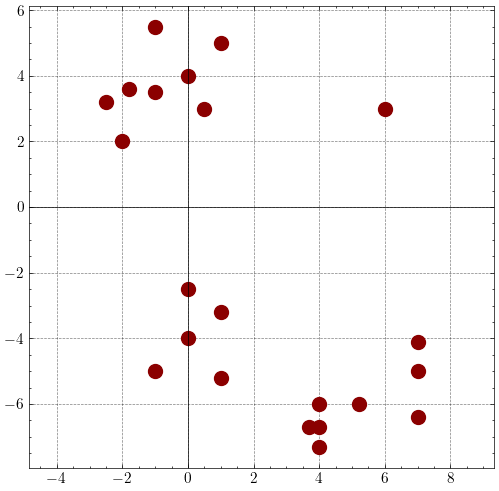

In [278]:
# read (big) dataset and name dimensions
bigd = pd.read_csv('data/big-dataset.csv', header=None)
bigd.columns = ['x', 'y']

# visualize
plt.figure(figsize=(6, 6))

plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)
plt.scatter(bigd.x, bigd.y, s=100, color="darkred")
plt.axis('equal')

plt.savefig('output/dataviz.png', dpi=dpi)
plt.show()

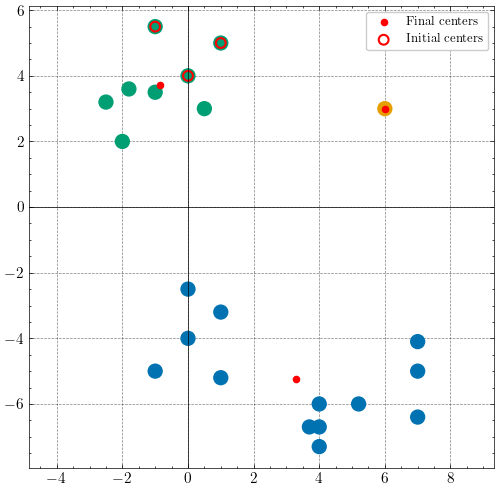

In [279]:
# fitting k means with hand-picked initial centers
colors = ListedColormap(['#0072B2', '#E69F00', '#009E73'])

X = bigd[['x', 'y']].to_numpy()
centers = np.array([[0,4], [1,5], [-1,5.5]])

model = KMeans(n_clusters=3, init=centers, n_init=1)
model.fit(X)

# visualize
plt.figure(figsize=(6, 6))
plt.axhline(0, color='black', lw=0.5)
plt.axvline(0, color='black', lw=0.5)

plt.scatter(bigd.x, bigd.y, c=model.labels_, cmap=colors, s=100)

plt.scatter(*model.cluster_centers_.T, color='red', s=20, label='Final centers')

plt.scatter(*centers.T, facecolors='none', edgecolors='red',
            marker='o', s=50, linewidths=1.5, label='Initial centers')

plt.axis('equal')
plt.legend()
plt.savefig('output/cluster_handpicked_initialization.png', dpi=dpi)
plt.show()

In [280]:
def repeated_kmeans(
        repetations=40, init='uniform', random_state=69,
        cluster_colors=colors, savefig_name='output/fig.png',
    ):

    # only used for uniformly drawn initializations
    rng = np.random.default_rng(42)

    # used for both
    results = []

    # 40 random initializations
    for _ in range(repetations):
        centers = X[rng.choice(len(X), size=3, replace=False)].copy()

        if init == 'k-means++':
            model = KMeans(n_clusters=3, init='k-means++', n_init=1, random_state=random_state)
        elif init == 'uniform':
            model = KMeans(n_clusters=3, init=centers, n_init=1)
        else: 
            Warning('Choose either k-means++ or uniform as initialization method:).')
            
        model.fit(X)

        results.append((model.inertia_, centers, model))

    # select lowest loss
    best_loss = min(r[0] for r in results)
    n_best = sum(np.isclose(r[0], best_loss) for r in results)
    _, centers, model = min(results, key=lambda r: r[0])

    print(f"Lowest k-means loss: {best_loss:.4f}")
    print(f"Minimum encountered: {n_best}/40 times")

    plt.figure(figsize=(5.5, 5.5))
    plt.axhline(0, color='black', lw=0.5)
    plt.axvline(0, color='black', lw=0.5)

    # data points colored by final cluster
    plt.scatter(bigd.x, bigd.y, c=model.labels_, cmap=cluster_colors, s=100)

    # final centers
    plt.scatter(*model.cluster_centers_.T, color='red', s=30,
                label='Final centers')

    plt.axis('equal')
    plt.legend()
    plt.savefig(savefig_name, dpi=dpi)
    plt.show()

Lowest k-means loss: 93.6729
Minimum encountered: 17/40 times


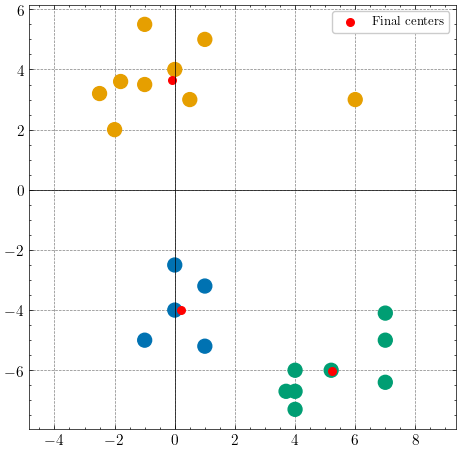

In [281]:
repeated_kmeans(
    repetations=40, init='uniform', cluster_colors=colors,
    savefig_name='output/cluster_uniform_minimizing_kmeansloss.png'
)

Lowest k-means loss: 93.6729
Minimum encountered: 40/40 times


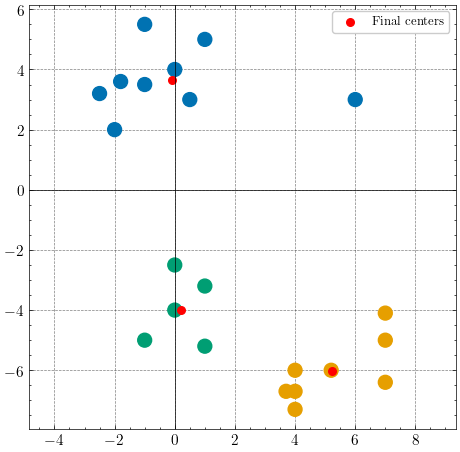

In [282]:
repeated_kmeans(
    repetations=40, init='k-means++', cluster_colors=colors,
    savefig_name='output/cluster_kmeanspp_minimizing_kmeansloss.png'
)

In [283]:
# read in data 
datavis = pd.read_csv('data/vis-dataset.csv', header=None)
datavis.columns = ['x', 'y', 'z']
datavis['h'] = [0]*2000 + [1]*2000
datavis['z'] = datavis['z']

display(datavis.head())
display(datavis.tail())

,x,y,z,h
0,-1.013109,-2.330220,0.070983,0
1,-0.606634,-1.842636,-0.058558,0
2,-1.977246,-2.392645,-0.087200,0
3,-2.030520,-2.437415,0.042715,0
4,-0.745145,-0.849566,0.020319,0


,x,y,z,h
3995,1.450603,-0.944378,0.282363,1
3996,1.477800,-0.945047,-0.224877,1
3997,1.424173,0.445926,0.864289,1
3998,1.590760,-0.010445,1.018304,1
3999,1.587895,-0.703215,0.678885,1


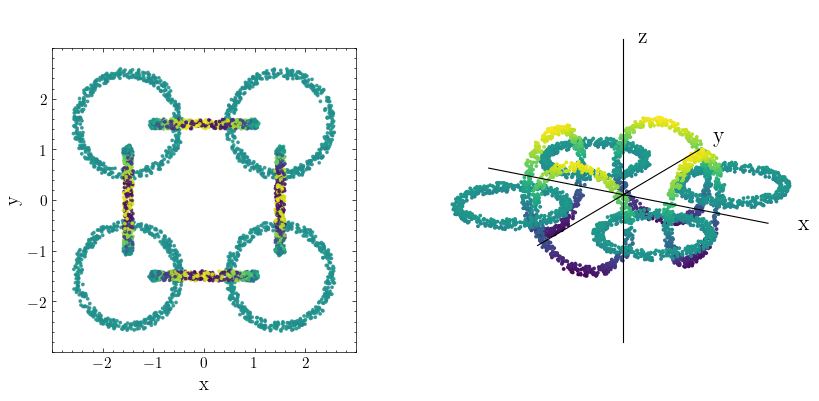

In [284]:
ticks = [-2, -1, 0, 1, 2]
fig = plt.figure(figsize=(9,4))

# -----------------
# 2D plot
# -----------------
ax1 = fig.add_axes([0.07, 0.12, 0.36, 0.76])

ax1.scatter(
    datavis.x, datavis.y,
    c=datavis.z, cmap='viridis',
    s=3, alpha=0.8
)

ax1.set_xlim(-3, 3)
ax1.set_ylim(-3, 3)
ax1.set_xticks(ticks)
ax1.set_yticks(ticks)
ax1.set_xlabel('x', fontsize=14)
ax1.set_ylabel('y', fontsize=14)
ax1.set_aspect('equal', adjustable='box')
ax1.grid(False)

# -----------------
# 3D plot
# -----------------
ax2 = fig.add_axes([0.43, 0.01, 0.56, 0.98], projection='3d')

ax2.scatter(
    datavis.x, datavis.y, datavis.z,
    c=datavis.z, cmap='viridis',
    s=3, depthshade=False
)

ax2.set(xlim=(-3.8, 3.8), ylim=(-3.8, 3.8), zlim=(-3.8, 3.8))
ax2.set_box_aspect((1, 1, 1), zoom=1.75)
ax2.view_init(elev=20, azim=-60)

# Remove default axes, grids, ticks and panes
ax2.set_axis_off()

# Draw centered axes from -3 to 3
ax2.plot([-3, 3], [0, 0], [0, 0], 'k-', lw=0.8)
ax2.plot([0, 0], [-3, 3], [0, 0], 'k-', lw=0.8)
ax2.plot([0, 0], [0, 0], [-3, 3], 'k-', lw=0.8)

# Axis labels
ax2.text(3.6, 0, 0, 'x', fontsize=16)
ax2.text(0, 3.6, 0, 'y', fontsize=16)
ax2.text(0.3, 0.0, 3.0, 'z', fontsize=16)

plt.show()

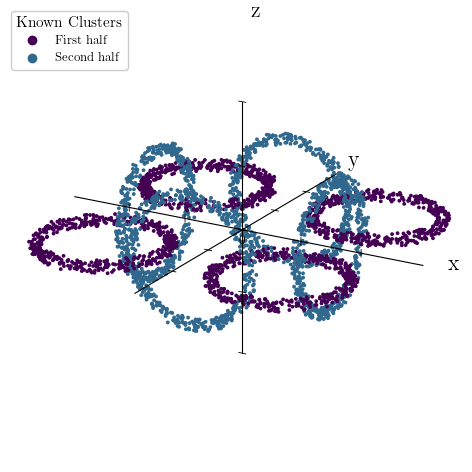

In [ ]:
# plotting
ticks = [-2, -1, 0, 1, 2]
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")

points = ax.scatter(
    datavis.x, datavis.y, datavis.z,
    c=datavis.h,
    cmap = ListedColormap(["#440154", "#31688E"])
    vmin=0, vmax=1,
    s=3, depthshade=False
)

ax.set(xlim=(-3.8, 3.8), ylim=(-3.8, 3.8), zlim=(-3.8, 3.8))
ax.set_box_aspect((1, 1, 1), zoom=1.85)
ax.view_init(elev=20, azim=-60)
ax.set_axis_off()

# Centered axes
ax.plot([-3, 3], [0, 0], [0, 0], "k-", lw=0.8)
ax.plot([0, 0], [-3, 3], [0, 0], "k-", lw=0.8)
ax.plot([0, 0], [0, 0], [-2, 2], "k-", lw=0.8)

# Custom ticks on the centered axes
for t in ticks:
    ax.plot([t, t], [0, 0], [-0.06, 0.06], "k-", lw=0.6)
    ax.plot([-0.06, 0.06], [t, t], [0, 0], "k-", lw=0.6)
    ax.plot([-0.06, 0.06], [0, 0], [t, t], "k-", lw=0.6)

ax.text(0, 0, -0.22, "0", ha="center", fontsize=9)

# Axis labels
ax.text(3.4, 0, 0, "x", fontsize=16)
ax.text(0, 3.4, 0, "y", fontsize=16)
ax.text(0.15, 0, 3.3, "z", fontsize=16)

# Discrete legend for h
handles, _ = points.legend_elements(num=[0, 1])
ax.legend(handles, ['First half', 'Second half'], title="Known Clusters", loc="upper left")

plt.show()

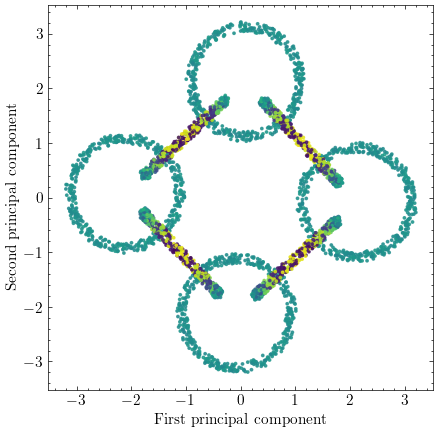

Explained variance ratio: [0.48237505 0.4608992 ]
Principal component directions:
 [[-0.67833657  0.73474546  0.00293509]
 [ 0.73475114  0.67833377  0.0020144 ]]


In [286]:
from sklearn.decomposition import PCA

# Find first two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(datavis[['x', 'y', 'z']])

# Plot projection onto the first two principal components
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=datavis.z, cmap='viridis',
    s=3, alpha=0.8
)

ax.set_xlabel('First principal component')
ax.set_ylabel('Second principal component')
ax.set_aspect('equal')
ax.grid(False)

plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Principal component directions:\n", pca.components_)

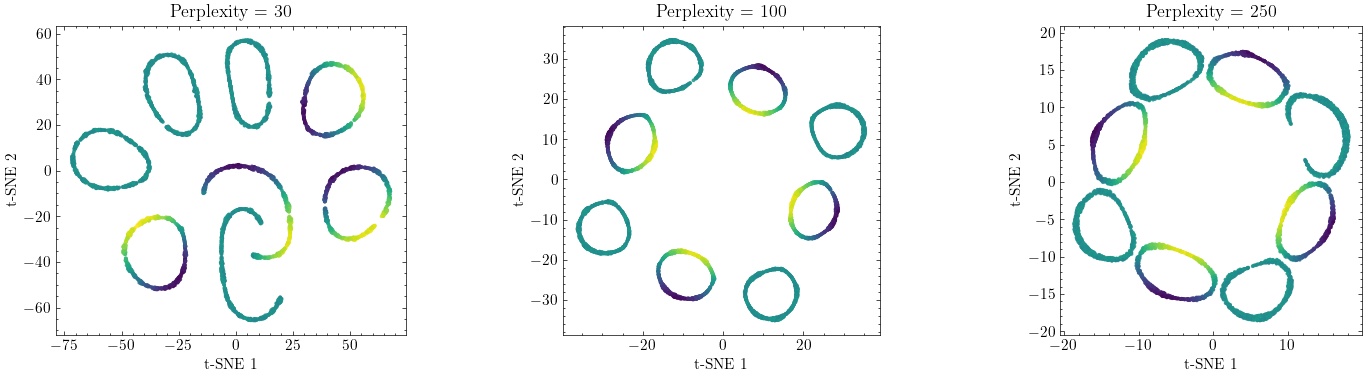

In [287]:
from sklearn.manifold import TSNE
import numpy as np

X = datavis[['x', 'y', 'z']].to_numpy()

# Same random initialization for all three
rng = np.random.default_rng(42)
init = rng.normal(0, 1e-4, size=(len(X), 2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, perplexity in zip(axes, [30, 100, 250]):

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init=init.copy(),
        random_state=42
    )

    X_tsne = tsne.fit_transform(X)

    ax.scatter(
        X_tsne[:, 0], X_tsne[:, 1],
        c=datavis.z, cmap='viridis',
        s=3, alpha=0.8
    )

    ax.set_title(f'Perplexity = {perplexity}')
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.set_aspect('equal')
    ax.grid(False)

plt.tight_layout()
plt.show()

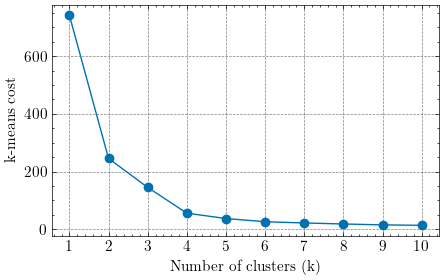

In [288]:
# k-means cost for different numbers of clusters (for data.csv / data.txt)
data = pd.read_csv('data/data.csv', header=None)
data = data.to_numpy()

ks = range(1, 11)
losses = []

for k in ks:
    model = KMeans(n_clusters=k, init='k-means++',
                   n_init=40, random_state=42)
    model.fit(data)
    losses.append(model.inertia_)

# visualize
plt.figure(figsize=(5, 3))
plt.plot(ks, losses, 'o-', color='#0072B2')
plt.xlabel('Number of clusters (k)')
plt.ylabel('k-means cost')
plt.xticks(ks)

plt.savefig('output/elbow_plot.png', dpi=dpi)
plt.show()